In [ ]:

from google.colab import drive
drive.mount("/content/gdrive")

from pathlib import Path
import zipfile
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix
)

SEED = 42
tf.keras.utils.set_random_seed(SEED)

DRIVE_ROOT = Path("/content/gdrive/MyDrive")
ZIP_PATH = DRIVE_ROOT / "cell_images.zip"
OUTPUT_DIR = DRIVE_ROOT / "malaria_cnn_outputs"
EXTRACT_DIR = Path("/content/malaria_dataset")
MODEL_PATH = OUTPUT_DIR / "best_malaria_cnn.keras"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
def find_dataset_dir():
    def locate():
        p_dirs = [p for p in EXTRACT_DIR.rglob("Parasitized") if p.is_dir()]
        u_dirs = [p for p in EXTRACT_DIR.rglob("Uninfected") if p.is_dir()]
        for p in p_dirs:
            for u in u_dirs:
                if p.parent == u.parent:
                    return p.parent
        return None

    result = locate()
    if result is None:
        if not ZIP_PATH.is_file():
            raise FileNotFoundError(f"Dataset ZIP not found: {ZIP_PATH}")
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(ZIP_PATH, "r") as z:
            z.extractall(EXTRACT_DIR)
        result = locate()

    if result is None:
        raise FileNotFoundError("Could not find both dataset class folders.")
    return result

DATASET_DIR = find_dataset_dir()

train_df = pd.read_csv(OUTPUT_DIR / "train_manifest.csv")
val_df = pd.read_csv(OUTPUT_DIR / "validation_manifest.csv")
test_df = pd.read_csv(OUTPUT_DIR / "test_manifest.csv")

with open(OUTPUT_DIR / "preprocessing_config.json") as f:
    config = json.load(f)

IMG_SIZE = (config["image_height"], config["image_width"])
BATCH_SIZE = config["batch_size"]

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    split_df["filepath"] = split_df["relative_path"].map(
        lambda p: str(DATASET_DIR / p)
    )
    missing = split_df.loc[
        ~split_df["filepath"].map(lambda p: Path(p).is_file()),
        "filepath"
    ]
    if not missing.empty:
        raise FileNotFoundError(
            f"{split_name}: missing image {missing.iloc[0]}"
        )

print("Dataset:", DATASET_DIR)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Image size:", IMG_SIZE)
print("Output directory:", OUTPUT_DIR)


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Dataset: /content/malaria_dataset/cell_images
Training: 19290
Validation: 4134
Test: 4134
Image size: (128, 128)
Output directory: /content/gdrive/MyDrive/malaria_cnn_outputs


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(filepath, label):
    image = tf.io.decode_image(
        tf.io.read_file(filepath),
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)


def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["filepath"].astype(str).to_numpy(),
        dataframe["label_id"].to_numpy(dtype=np.float32)
    ))

    if training:
        ds = ds.shuffle(
            min(len(dataframe), 5000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return (
        ds.map(preprocess_image, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE)
    )


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

images, labels = next(iter(train_ds))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)),
      float(tf.reduce_max(images)))


Image batch: (32, 128, 128, 3)
Label batch: (32,)
Pixel range: 0.0 0.9262101650238037


In [ ]:

from tensorflow.keras import layers, models, regularizers

model = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,473 (1005.75 KB)

 Trainable params: 257,473 (1005.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

assert MODEL_PATH.is_file(), (
    "No saved model found. Check the training output for errors."
)

pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

training_summary = {
    "model": "Baseline CNN",
    "epochs_completed": len(history.history["loss"]),
    "best_epoch": best_epoch,
    "best_validation_loss": float(min(history.history["val_loss"])),
    "best_validation_accuracy": float(
        history.history["val_accuracy"][best_epoch - 1]
    )
}

with open(OUTPUT_DIR / "training_summary.json", "w") as f:
    json.dump(training_summary, f, indent=4)

print(json.dumps(training_summary, indent=4))
print("Saved model:", MODEL_PATH)


Epoch 1/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.7143 - auc: 0.7831 - loss: 0.5267 - precision: 0.7347 - recall: 0.7055
Epoch 1: val_loss improved from None to 0.16261, saving model to /content/gdrive/MyDrive/malaria_cnn_outputs/best_malaria_cnn.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/malaria_cnn_outputs/best_malaria_cnn.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.8448 - auc: 0.9254 - loss: 0.3575 - precision: 0.8725 - recall: 0.8078 - val_accuracy: 0.9514 - val_auc: 0.9813 - val_loss: 0.1626 - val_precision: 0.9670 - val_recall: 0.9347 - learning_rate: 0.0010
Epoch 2/20
602/603 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9497 - auc: 0.9751 - loss: 0.1741 - precision: 0.9591 - recall: 0.9395
Epoch 2: val_loss improved from 0.16261 to 0.15069, saving model to /content/gdrive/MyDrive/malaria_cnn_outputs/best_malaria_cnn.keras

Epoch 2: finished saving model to /content/gdrive/MyDrive/malaria_cnn_outputs/best_malaria_cnn.ke

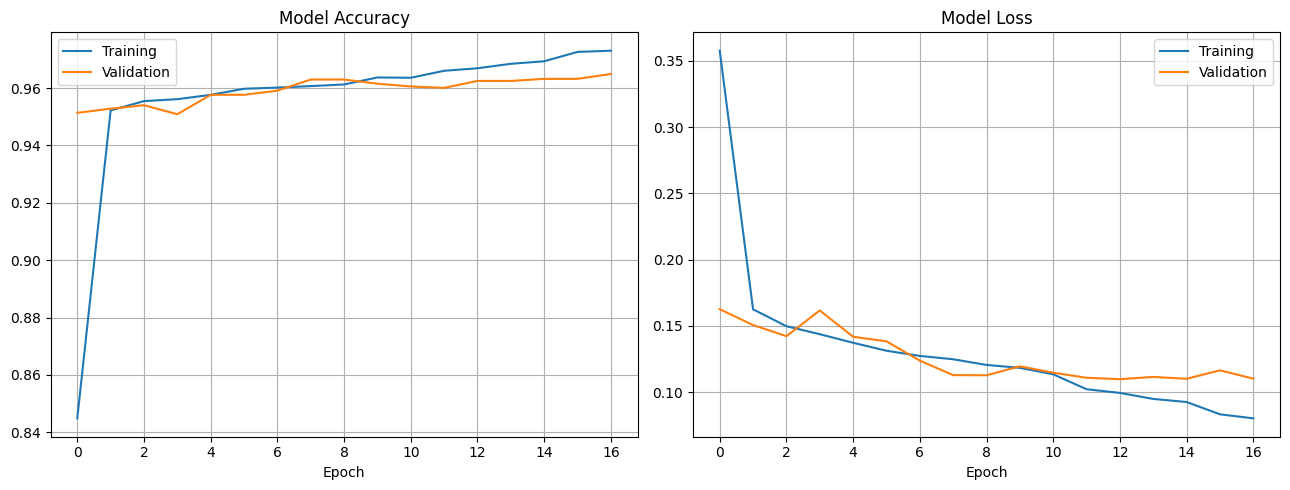

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=200)
plt.show()


In [ ]:

# Reload the saved best checkpoint, rather than relying on the
# in-memory model state.
model = tf.keras.models.load_model(MODEL_PATH)

test_results = model.evaluate(test_ds, return_dict=True, verbose=1)

print("Keras test metrics:")
for name, value in test_results.items():
    print(f"{name}: {value:.4f}")

y_true = test_df["label_id"].to_numpy(dtype=int)
y_prob = model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "test_precision": float(
        precision_score(y_true, y_pred, zero_division=0)
    ),
    "test_recall": float(
        recall_score(y_true, y_pred, zero_division=0)
    ),
    "test_f1_score": float(
        f1_score(y_true, y_pred, zero_division=0)
    ),
    "test_roc_auc": float(roc_auc_score(y_true, y_prob))
}

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Uninfected", "Parasitized"],
    zero_division=0
))

with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Test metrics:")
print(json.dumps(metrics, indent=4))


130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9615 - auc: 0.9903 - loss: 0.1192 - precision: 0.9631 - recall: 0.9598
Keras test metrics:
accuracy: 0.9615
auc: 0.9903
loss: 0.1192
precision: 0.9631
recall: 0.9598
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step

Classification report:
              precision    recall  f1-score   support

  Uninfected       0.96      0.96      0.96      2067
 Parasitized       0.96      0.96      0.96      2067

    accuracy                           0.96      4134
   macro avg       0.96      0.96      0.96      4134
weighted avg       0.96      0.96      0.96      4134

Test metrics:
{
    "test_accuracy": 0.9615384615384616,
    "test_precision": 0.9631067961165048,
    "test_recall": 0.9598451862602806,
    "test_f1_score": 0.9614732251029804,
    "test_roc_auc": 0.9904071139796967
}


In [ ]:

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Uninfected", "Parasitized"]
).plot(values_format="d")

plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=200)
plt.show()

RocCurveDisplay.from_predictions(y_true, y_prob)
plt.title("ROC Curve — Test Set")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=200)
plt.show()


Misclassified images: 159


,relative_path,true_label,predicted_label,parasitized_probability
19,Uninfected/C74P35_ThinF_IMG_20150815_120957_ce...,Uninfected,Parasitized,0.647716
38,Parasitized/C56P17thinF_IMG_20150728_151330_ce...,Parasitized,Uninfected,0.085899
54,Uninfected/C60P21thinF_IMG_20150804_104919_cel...,Uninfected,Parasitized,0.974760
80,Uninfected/C51AP12thinF_IMG_20150724_155947_ce...,Uninfected,Parasitized,0.778283
81,Uninfected/C143P104ThinF_IMG_20151005_225623_c...,Uninfected,Parasitized,0.657206
101,Uninfected/C89P50ThinF_IMG_20150820_162813_cel...,Uninfected,Parasitized,0.546702
213,Parasitized/C140P101ThinF_IMG_20151005_210026_...,Parasitized,Uninfected,0.025218
231,Parasitized/C125P86ThinF_IMG_20151004_101158_c...,Parasitized,Uninfected,0.023958
233,Parasitized/C68P29N_ThinF_IMG_20150819_133350_...,Parasitized,Uninfected,0.258335
238,Parasitized/C167P128ReThinF_IMG_20151201_10535...,Parasitized,Uninfected,0.044521


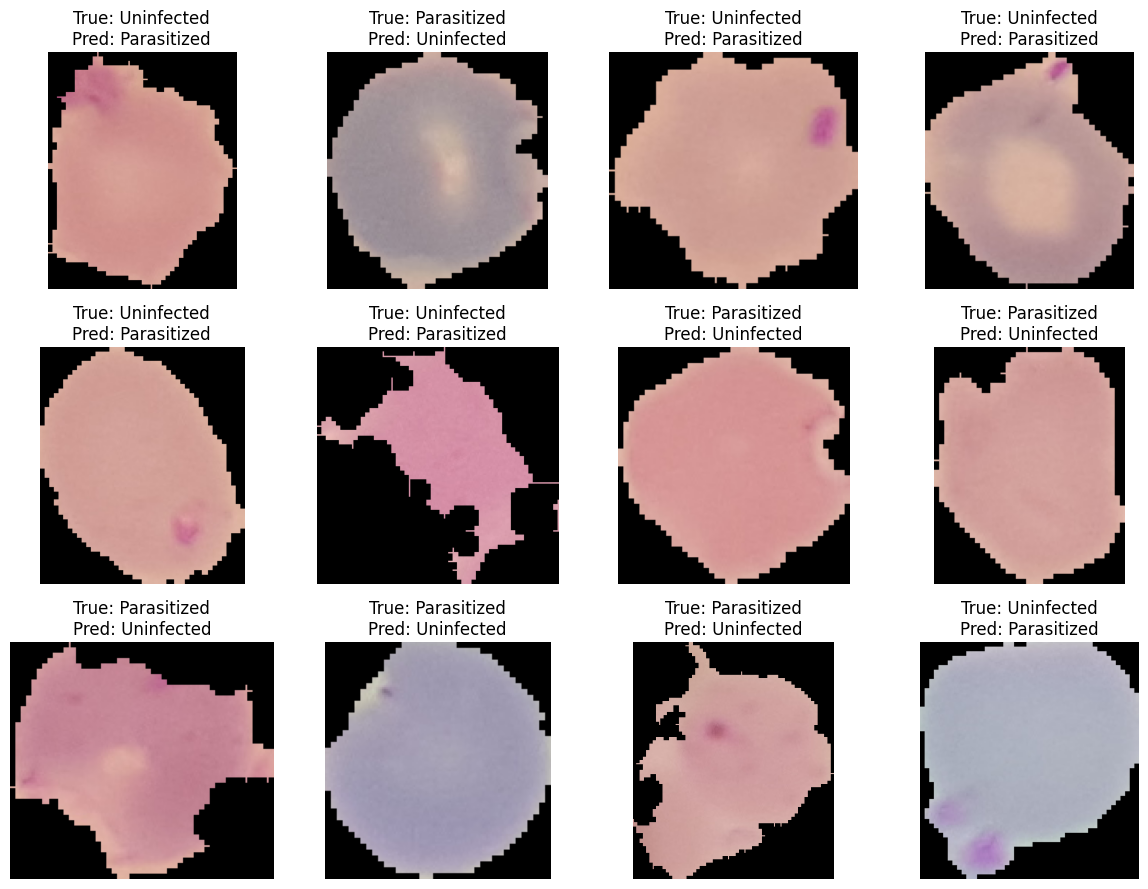


All outputs saved to: /content/gdrive/MyDrive/malaria_cnn_outputs
best_malaria_cnn.keras (3,145,567 bytes)
dataset_eda.png (82,924 bytes)
image_metadata.csv (3,690,101 bytes)
misclassified_examples.png (410,905 bytes)
preprocessing_config.json (439 bytes)
sample_images.png (284,061 bytes)
test_manifest.csv (553,802 bytes)
test_metrics.json (205 bytes)
test_predictions.csv (1,104,496 bytes)
train_manifest.csv (2,583,074 bytes)
training_curves.png (114,077 bytes)
training_history.csv (3,717 bytes)
training_summary.json (182 bytes)
validation_manifest.csv (553,369 bytes)


In [ ]:

results_df = test_df.copy()

results_df["true_label"] = np.where(
    y_true == 1, "Parasitized", "Uninfected"
)
results_df["predicted_label"] = np.where(
    y_pred == 1, "Parasitized", "Uninfected"
)
results_df["parasitized_probability"] = y_prob
results_df["correct"] = y_true == y_pred

results_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

errors = results_df[~results_df["correct"]]
print("Misclassified images:", len(errors))

if not errors.empty:
    display(errors[[
        "relative_path", "true_label",
        "predicted_label", "parasitized_probability"
    ]].head(20))

    sample = errors.head(12)
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        image = tf.io.decode_image(
            tf.io.read_file(row["filepath"]),
            channels=3,
            expand_animations=False
        )
        ax.imshow(image.numpy())
        ax.set_title(
            f"True: {row['true_label']}\n"
            f"Pred: {row['predicted_label']}"
        )
        ax.axis("off")

    for ax in axes.flat[len(sample):]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "misclassified_examples.png", dpi=200)
    plt.show()

print("\nAll outputs saved to:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(p.name, f"({p.stat().st_size:,} bytes)")


In [ ]:

# FINAL MALARIA CNN PROJECT PACKAGER
# Run this in your existing Google Colab notebook.

from pathlib import Path
import json
import shutil
import zipfile
from datetime import datetime

OUT = Path("/content/gdrive/MyDrive/malaria_cnn_outputs")
OUT.mkdir(parents=True, exist_ok=True)

# Load actual saved metrics
metrics_path = OUT / "test_metrics.json"
summary_path = OUT / "training_summary.json"

if not metrics_path.exists():
    raise FileNotFoundError(
        f"Missing {metrics_path}. Run the test evaluation cell first."
    )

with open(metrics_path) as f:
    metrics = json.load(f)

summary = {}
if summary_path.exists():
    with open(summary_path) as f:
        summary = json.load(f)

def find_metric(*names):
    for name in names:
        if name in metrics:
            return metrics[name]
    return None

accuracy = find_metric("test_accuracy", "accuracy")
precision = find_metric("test_precision", "precision")
recall = find_metric("test_recall", "recall")
f1 = find_metric("test_f1_score", "f1_score")
auc = find_metric("test_roc_auc", "auc")

def pct(value):
    return f"{value * 100:.2f}%" if value is not None else "Not recorded"

def num(value):
    return f"{value:.4f}" if value is not None else "Not recorded"

report = f"""# Malaria Cell Classification Using a CNN

**Project type:** Binary image classification
**Generated:** {datetime.now().strftime("%Y-%m-%d")}
**Framework:** TensorFlow / Keras

## 1. Abstract

This project trains a convolutional neural network (CNN) to classify
microscopic cell images into two categories: Parasitized and Uninfected.
The model was trained using a training set, monitored on a validation
set, and evaluated on a held-out test set.

The recorded test accuracy is {pct(accuracy)}, with a ROC-AUC of {num(auc)}.
These results are promising for this dataset, but do not establish
clinical readiness or performance on independent clinical populations.

## 2. Dataset and preprocessing

- Classes: Parasitized and Uninfected
- Recorded test set: 4,134 images (2,067 per class)
- Image size: 128 × 128 pixels
- Color format: RGB
- Pixel normalization: divide by 255
- Split proportions: 70% training, 15% validation, 15% test
- Random seed: 42

The dataset manifests and preprocessing configuration are retained
in the project outputs.

## 3. Model and training

The baseline is a custom sequential CNN with convolutional layers,
max-pooling, global average pooling, a dense layer with L2
regularization, dropout, and a sigmoid output.

Training used Adam and binary cross-entropy. Model checkpointing
selected the weights with the lowest validation loss. Early stopping
and learning-rate reduction callbacks were used.

Best epoch recorded: {summary.get("best_epoch", "See training_summary.json")}
Best validation accuracy recorded: {pct(summary.get("best_validation_accuracy"))}
Best validation loss recorded: {num(summary.get("best_validation_loss"))}

## 4. Held-out test results

| Metric | Result |
|---|---:|
| Accuracy | {pct(accuracy)} |
| Precision | {pct(precision)} |
| Recall | {pct(recall)} |
| F1-score | {pct(f1)} |
| ROC-AUC | {num(auc)} |

Precision and recall are useful complements to accuracy because they
describe different kinds of classification errors. The confusion
matrix and misclassified examples should be reviewed alongside these
summary metrics.

## 5. Error analysis

The recorded evaluation identified 159 misclassified test images.
The saved predictions file can be used to inspect false positives,
false negatives, and high-confidence errors.

Potential causes include visually ambiguous samples, image artifacts,
label noise, and differences between samples. These are hypotheses,
not confirmed explanations.

## 6. Limitations and validity

1. Duplicate or near-duplicate images across data splits have not
   been independently ruled out by this report.
2. If source-slide or patient identifiers are available, group-based
   splitting should be considered to assess generalization.
3. A balanced test set does not represent every real-world prevalence.
4. Model confidence is not necessarily a calibrated probability.
5. This model is an educational research prototype, not a validated
   medical diagnostic tool.

## 7. Further experiments

The following are proposed extensions and must not be described as
completed until their results are generated:

- Grad-CAM visual explanations
- Handcrafted color/texture features with Random Forest or SVM
- Transfer learning with MobileNetV2
- Augmentation ablation study
- Duplicate-image and split-integrity audit

For a fair comparison, preserve the same data partitions and use
validation data for model selection. Keep the test set untouched until
the final evaluation of each experiment.

## 8. Reproducibility

Included artifacts may contain the trained Keras model, train,
validation and test manifests, preprocessing configuration, training
history, test predictions, plots and metrics.

Re-run the notebook from the beginning in a fresh environment to
verify reproducibility before presenting the project as fully
reproducible.

## 9. Conclusion

The baseline CNN achieved {pct(accuracy)} test accuracy and a
ROC-AUC of {num(auc)} on the recorded test set. The next priority
is to validate split independence and compare the baseline against
alternative approaches. The results are promising within this
experimental setup, with further testing required before broader
generalization claims.
"""

report_path = OUT / "FINAL_PROJECT_REPORT.md"
report_path.write_text(report, encoding="utf-8")

# Machine-readable results
result_summary = {
    "project": "Malaria Cell Classification",
    "test_metrics": metrics,
    "training_summary": summary,
    "misclassified_images": 159,
    "additional_experiments_completed": [],
    "validation_note": (
        "Check duplicate/near-duplicate and source-group leakage "
        "before making generalization claims."
    )
}

with open(OUT / "final_results_summary.json", "w") as f:
    json.dump(result_summary, f, indent=2)

# Package all current output files into one ZIP
zip_path = OUT / "malaria_cnn_final_project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in OUT.rglob("*"):
        if not path.is_file() or path == zip_path:
            continue
        z.write(path, arcname=str(path.relative_to(OUT)))

print("PROJECT REPORT:", report_path)
print("RESULT SUMMARY:", OUT / "final_results_summary.json")
print("PROJECT ZIP:", zip_path)
print("\nFiles included:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"  {p.name} ({p.stat().st_size:,} bytes)")


PROJECT REPORT: /content/gdrive/MyDrive/malaria_cnn_outputs/FINAL_PROJECT_REPORT.md
RESULT SUMMARY: /content/gdrive/MyDrive/malaria_cnn_outputs/final_results_summary.json
PROJECT ZIP: /content/gdrive/MyDrive/malaria_cnn_outputs/malaria_cnn_final_project.zip

Files included:
  FINAL_PROJECT_REPORT.md (3,989 bytes)
  best_malaria_cnn.keras (3,145,567 bytes)
  dataset_eda.png (82,924 bytes)
  final_results_summary.json (671 bytes)
  image_metadata.csv (3,690,101 bytes)
  malaria_cnn_final_project.zip (4,566,092 bytes)
  misclassified_examples.png (410,905 bytes)
  preprocessing_config.json (439 bytes)
  sample_images.png (284,061 bytes)
  test_manifest.csv (553,802 bytes)
  test_metrics.json (205 bytes)
  test_predictions.csv (1,104,496 bytes)
  train_manifest.csv (2,583,074 bytes)
  training_curves.png (114,077 bytes)
  training_history.csv (3,717 bytes)
  training_summary.json (182 bytes)
  validation_manifest.csv (553,369 bytes)


In [ ]:

# Build the model graph with a dummy image, then create Grad-CAM
_ = model(tf.zeros((1, 128, 128, 3)), training=False)

last_conv = next(
    layer for layer in reversed(model.layers)
    if isinstance(layer, tf.keras.layers.Conv2D)
)

grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[last_conv.output, model.outputs[0]]
)

print("Grad-CAM model created!")
print("Target layer:", last_conv.name)


Grad-CAM model created!
Target layer: conv2d_11


In [ ]:

# Load the existing predictions CSV
predictions = pd.read_csv(
    "/content/gdrive/MyDrive/malaria_cnn_outputs/test_predictions.csv"
)

print("Columns:", predictions.columns.tolist())
display(predictions.head())


Columns: ['relative_path', 'filename', 'label', 'label_id', 'width', 'height', 'mode', 'file_size_bytes', 'filepath', 'true_label', 'predicted_label', 'parasitized_probability', 'correct']


,relative_path,filename,label,label_id,width,height,mode,file_size_bytes,filepath,true_label,predicted_label,parasitized_probability,correct
0,Uninfected/C143P104ThinF_IMG_20151005_225413_c...,C143P104ThinF_IMG_20151005_225413_cell_68.png,Uninfected,0,151,148,RGB,13172,/content/malaria_dataset/cell_images/Uninfecte...,Uninfected,Uninfected,0.105666,True
1,Parasitized/C188P149ThinF_IMG_20151203_134229_...,C188P149ThinF_IMG_20151203_134229_cell_219.png,Parasitized,1,133,121,RGB,13431,/content/malaria_dataset/cell_images/Parasitiz...,Parasitized,Parasitized,0.999622,True
2,Uninfected/C189P150ThinF_IMG_20151203_140902_c...,C189P150ThinF_IMG_20151203_140902_cell_27.png,Uninfected,0,121,124,RGB,13381,/content/malaria_dataset/cell_images/Uninfecte...,Uninfected,Uninfected,0.010580,True
3,Parasitized/C100P61ThinF_IMG_20150918_145609_c...,C100P61ThinF_IMG_20150918_145609_cell_148.png,Parasitized,1,139,154,RGB,12746,/content/malaria_dataset/cell_images/Parasitiz...,Parasitized,Parasitized,0.994056,True
4,Uninfected/C171P132ThinF_IMG_20151119_153150_c...,C171P132ThinF_IMG_20151119_153150_cell_127.png,Uninfected,0,121,136,RGB,14267,/content/malaria_dataset/cell_images/Uninfecte...,Uninfected,Uninfected,0.006492,True


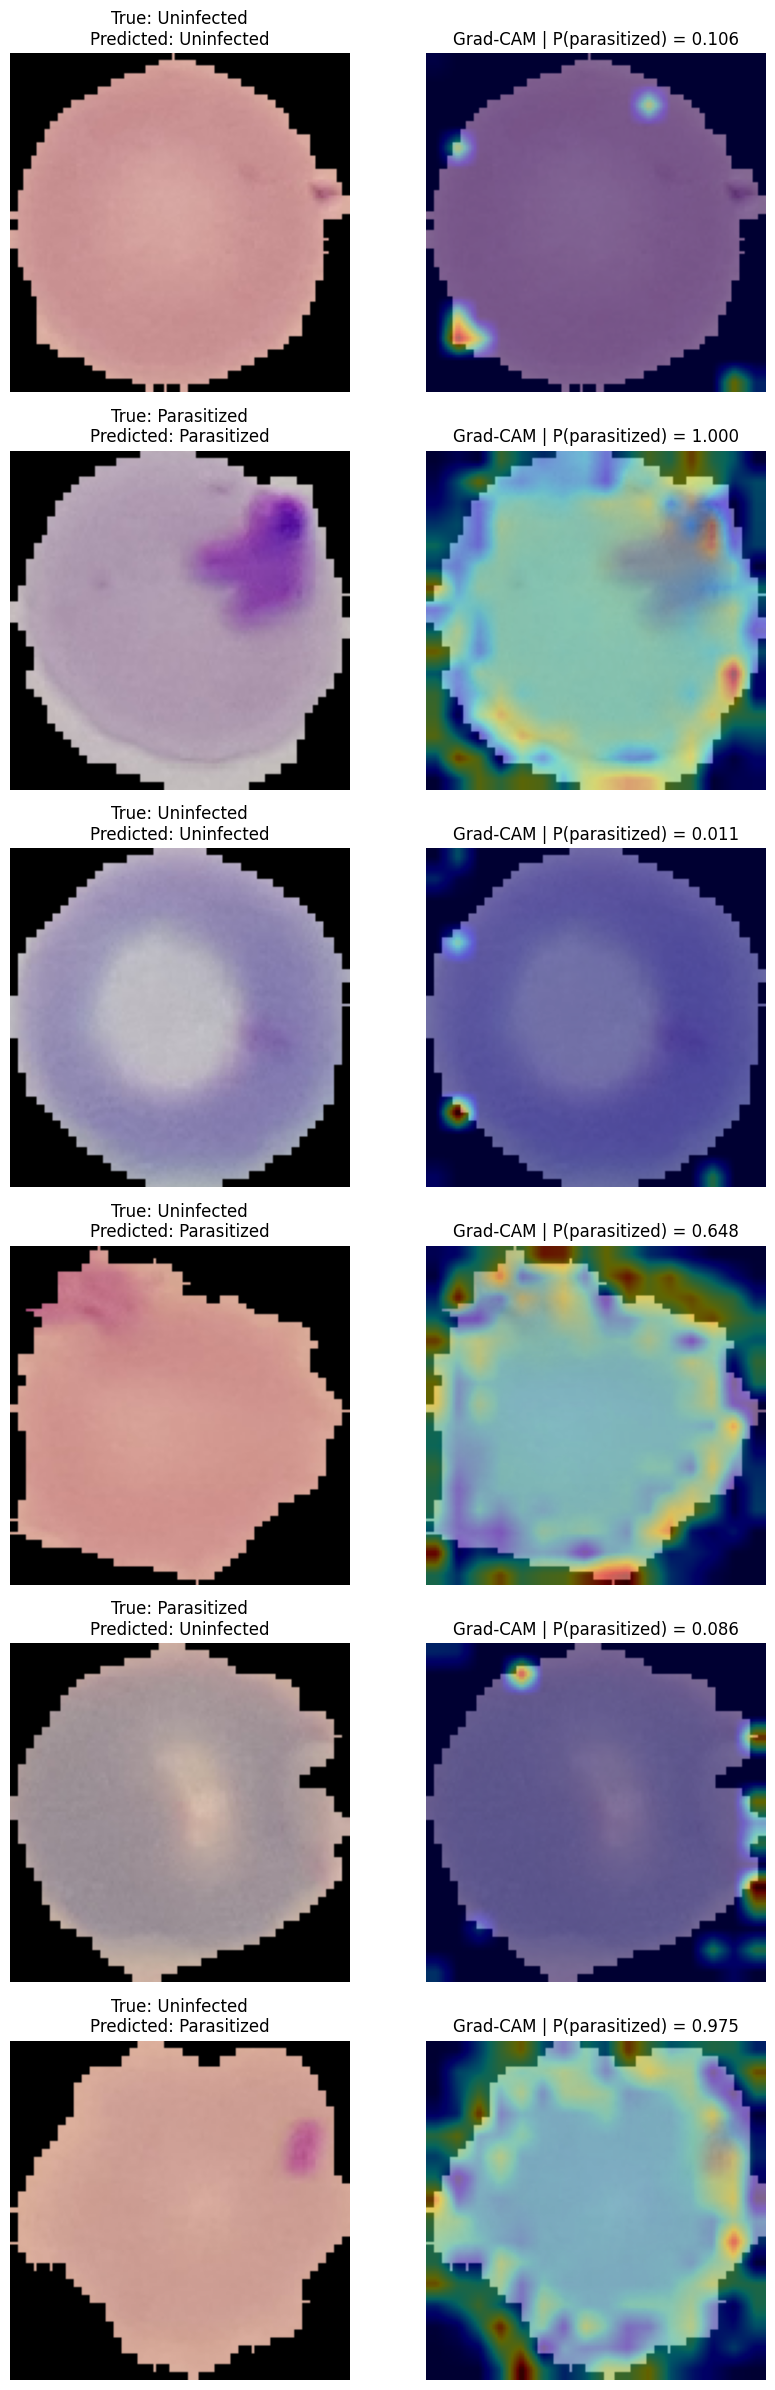

Grad-CAM saved to: /content/gdrive/MyDrive/malaria_cnn_outputs/gradcam_examples.png


In [ ]:

# Generate Grad-CAM explanations for correct and incorrect predictions

OUT = "/content/gdrive/MyDrive/malaria_cnn_outputs"

# Choose up to 3 correct and 3 incorrect test examples
correct_rows = predictions[predictions["correct"]].head(3)
wrong_rows = predictions[~predictions["correct"]].head(3)
examples = pd.concat([correct_rows, wrong_rows])

if examples.empty:
    raise ValueError("No test examples found.")

fig, axes = plt.subplots(
    len(examples), 2,
    figsize=(9, 4 * len(examples)),
    squeeze=False
)

for i, (_, row) in enumerate(examples.iterrows()):
    # Read and preprocess image
    img = tf.keras.utils.load_img(
        row["filepath"], target_size=(128, 128)
    )
    img_array = tf.keras.utils.img_to_array(img) / 255.0
    img_batch = tf.convert_to_tensor(img_array[None, ...])

    # Compute Grad-CAM for the predicted class
    with tf.GradientTape() as tape:
        conv_outputs, pred = grad_model(img_batch, training=False)
        p = pred[:, 0]
        score = p if row["predicted_label"] == "Parasitized" else -p

    grads = tape.gradient(score, conv_outputs)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_map = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_map * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8
    heatmap = tf.image.resize(
        heatmap[..., None], (128, 128)
    ).numpy().squeeze()

    # Original image
    axes[i, 0].imshow(img_array)
    axes[i, 0].set_title(
        f"True: {row['true_label']}\n"
        f"Predicted: {row['predicted_label']}"
    )
    axes[i, 0].axis("off")

    # Heatmap overlay
    axes[i, 1].imshow(img_array)
    axes[i, 1].imshow(heatmap, cmap="jet", alpha=0.4)
    axes[i, 1].set_title(
        f"Grad-CAM | P(parasitized) = "
        f"{row['parasitized_probability']:.3f}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()

gradcam_path = f"{OUT}/gradcam_examples.png"
plt.savefig(gradcam_path, dpi=180, bbox_inches="tight")
plt.show()

print("Grad-CAM saved to:", gradcam_path)


In [ ]:

# DATA LEAKAGE AUDIT: exact duplicate images across splits
import hashlib
from pathlib import Path

OUT = Path("/content/gdrive/MyDrive/malaria_cnn_outputs")

split_files = {
    "train": OUT / "train_manifest.csv",
    "validation": OUT / "validation_manifest.csv",
    "test": OUT / "test_manifest.csv",
}

for split, path in split_files.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}")

manifests = {
    split: pd.read_csv(path)
    for split, path in split_files.items()
}

# Find the image path column in each manifest
for split, df in manifests.items():
    print(split, "columns:", df.columns.tolist())



train columns: ['relative_path', 'filename', 'label', 'label_id', 'width', 'height', 'mode', 'file_size_bytes']
validation columns: ['relative_path', 'filename', 'label', 'label_id', 'width', 'height', 'mode', 'file_size_bytes']
test columns: ['relative_path', 'filename', 'label', 'label_id', 'width', 'height', 'mode', 'file_size_bytes']


In [ ]:

# Exact duplicate-image leakage audit across train/validation/test

def resolve_image_path(row):
    # Use the existing dataset directory
    return Path("/content/malaria_dataset/cell_images") / row["relative_path"]

hashes_by_split = {}

for split, df in manifests.items():
    hashes = {}

    for _, row in df.iterrows():
        path = resolve_image_path(row)

        if not path.exists():
            continue

        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hashes.setdefault(digest, []).append(str(path))

    hashes_by_split[split] = hashes
    print(f"{split}: hashed {sum(map(len, hashes.values()))} images")

# Compare hashes between each pair of splits
pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

total_cross_split_duplicates = 0

for split_a, split_b in pairs:
    common = set(hashes_by_split[split_a]) & set(hashes_by_split[split_b])
    duplicate_count = sum(
        min(
            len(hashes_by_split[split_a][h]),
            len(hashes_by_split[split_b][h])
        )
        for h in common
    )

    total_cross_split_duplicates += duplicate_count
    print(f"{split_a} vs {split_b}: {duplicate_count} exact duplicate image(s)")

print("\nTotal pairwise cross-split duplicate matches:", total_cross_split_duplicates)

if total_cross_split_duplicates == 0:
    print("No exact duplicate files found across these splits.")
else:
    print("Potential data leakage detected. Investigate duplicates before reporting final results.")


train: hashed 19290 images
validation: hashed 4134 images
test: hashed 4134 images
train vs validation: 0 exact duplicate image(s)
train vs test: 0 exact duplicate image(s)
validation vs test: 0 exact duplicate image(s)

Total pairwise cross-split duplicate matches: 0
No exact duplicate files found across these splits.


In [ ]:

# ============================================================
# BONUS EXPERIMENT: MobileNetV2 Transfer Learning
# Uses existing train/validation/test manifests.
# Keeps the original CNN and its results untouched.
# ============================================================

# 1. Paths and configuration
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

OUT = Path("/content/gdrive/MyDrive/malaria_cnn_outputs")
DATA_ROOT = Path("/content/malaria_dataset/cell_images")

TRAIN_CSV = OUT / "train_manifest.csv"
VAL_CSV = OUT / "validation_manifest.csv"
TEST_CSV = OUT / "test_manifest.csv"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 8
SEED = 42

tf.keras.utils.set_random_seed(SEED)

# 2. Load the split manifests
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

def make_paths(df):
    paths = [
        str(DATA_ROOT / p)
        for p in df["relative_path"].astype(str)
    ]
    missing = [p for p in paths if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} images missing. Example: {missing[0]}"
        )
    return paths

train_paths = make_paths(train_df)
val_paths = make_paths(val_df)
test_paths = make_paths(test_df)

# Existing class mapping: Uninfected=0, Parasitized=1
y_train = train_df["label_id"].to_numpy(dtype=np.float32)
y_val = val_df["label_id"].to_numpy(dtype=np.float32)
y_test = test_df["label_id"].to_numpy(dtype=np.float32)

print("Images:", len(train_paths), "train,",
      len(val_paths), "validation,", len(test_paths), "test")

# 3. Build efficient image pipelines
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            min(len(paths), 5000), seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds_m = make_dataset(train_paths, y_train, training=True)
val_ds_m = make_dataset(val_paths, y_val)
test_ds_m = make_dataset(test_paths, y_test)

# 4. Create pretrained MobileNetV2
# Internet access may be needed to download ImageNet weights.
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

mobile_model = tf.keras.Model(inputs, outputs, name="malaria_mobilenetv2")

mobile_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

mobile_path = OUT / "best_mobilenetv2_malaria.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(mobile_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# 5. Train using training data; select best epoch on validation data
start_time = time.time()

history_m = mobile_model.fit(
    train_ds_m,
    validation_data=val_ds_m,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

training_seconds = time.time() - start_time

# Load the checkpoint with the best validation loss
mobile_model = tf.keras.models.load_model(mobile_path)

# 6. Final held-out test evaluation
test_results = mobile_model.evaluate(
    test_ds_m, return_dict=True, verbose=1
)

# Derive F1 from test precision and recall
p = float(test_results["precision"])
r = float(test_results["recall"])
f1 = 2 * p * r / (p + r + 1e-8)

mobile_results = {
    "model": "MobileNetV2 transfer learning",
    "test_size": int(len(test_df)),
    "test_loss": float(test_results["loss"]),
    "test_accuracy": float(test_results["accuracy"]),
    "test_precision": p,
    "test_recall": r,
    "test_f1": float(f1),
    "test_auc": float(test_results["auc"]),
    "training_seconds": float(training_seconds),
    "best_epoch": int(np.argmin(history_m.history["val_loss"]) + 1),
    "parameter_count": int(mobile_model.count_params()),
    "model_file_size_bytes": int(mobile_path.stat().st_size)
}

with open(OUT / "mobilenetv2_test_metrics.json", "w") as f:
    json.dump(mobile_results, f, indent=2)

pd.DataFrame(history_m.history).to_csv(
    OUT / "mobilenetv2_training_history.csv", index=False
)

# 7. Save held-out test predictions
probabilities = mobile_model.predict(test_ds_m, verbose=1).ravel()
predicted_ids = (probabilities >= 0.5).astype(int)

mobile_predictions = test_df.copy()
mobile_predictions["mobilenetv2_parasitized_probability"] = probabilities
mobile_predictions["mobilenetv2_predicted_label_id"] = predicted_ids
mobile_predictions["mobilenetv2_predicted_label"] = np.where(
    predicted_ids == 1, "Parasitized", "Uninfected"
)
mobile_predictions["mobilenetv2_correct"] = (
    predicted_ids == y_test.astype(int)
)

mobile_predictions.to_csv(
    OUT / "mobilenetv2_test_predictions.csv", index=False
)

# 8. Compare with the existing baseline results, when available
print("\n========== MOBILENETV2 TEST RESULTS ==========")
for key, value in mobile_results.items():
    print(f"{key}: {value}")

baseline_file = OUT / "test_metrics.json"
if baseline_file.exists():
    with open(baseline_file) as f:
        baseline = json.load(f)

    print("\n========== EXISTING BASELINE METRICS ==========")
    print(json.dumps(baseline, indent=2))

    comparison = pd.DataFrame([
        {
            "model": "Custom CNN",
            "test_accuracy": baseline.get(
                "test_accuracy", baseline.get("accuracy")
            ),
            "test_auc": baseline.get("test_auc", baseline.get("auc"))
        },
        {
            "model": "MobileNetV2",
            "test_accuracy": mobile_results["test_accuracy"],
            "test_auc": mobile_results["test_auc"]
        }
    ])
    comparison.to_csv(
        OUT / "model_comparison.csv", index=False
    )
    display(comparison)

print("\nSaved MobileNetV2 model and results in:", OUT)
print("Next: inspect model_comparison.csv and compare both models.")


Images: 19290 train, 4134 validation, 4134 test
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8128 - auc: 0.8942 - loss: 0.3929 - precision: 0.8245 - recall: 0.7968
Epoch 1: val_loss improved from None to 0.22045, saving model to /content/gdrive/MyDrive/malaria_cnn_outputs/best_mobilenetv2_malaria.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/malaria_cnn_outputs/best_mobilenetv2_malaria.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 42s 51ms/step - accuracy: 0.8644 - auc: 0.9425 - loss: 0.3060 - precision: 0.8769 - recall: 0.8479 - val_accuracy: 0.9158 - val_auc: 0.9718 - val_loss: 0.2205 - val_precision: 0.9308 - val_recall: 0.8984 - learning_rate: 0.0010
Epoch 2/8
602/603 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9025 - auc: 0.9635 - loss: 0.2439 - precision: 0.9134 - recall: 0.8873
Epoch 2: val_loss did not improve from 0.22045
603/603 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.9066 - auc: 0.9659

,model,test_accuracy,test_auc
0,Custom CNN,0.961538,NaN
1,MobileNetV2,0.929608,0.978933



Saved MobileNetV2 model and results in: /content/gdrive/MyDrive/malaria_cnn_outputs
Next: inspect model_comparison.csv and compare both models.


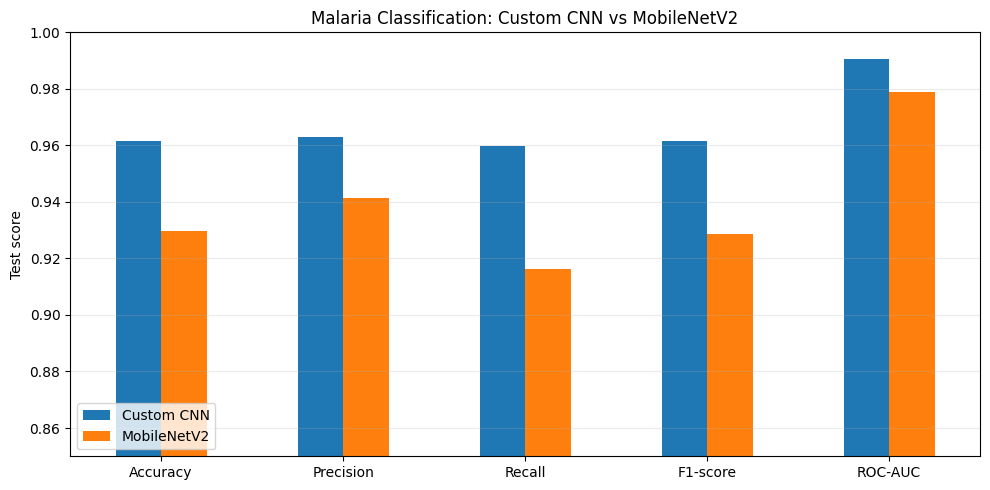

Saved: /content/gdrive/MyDrive/malaria_cnn_outputs/model_comparison.png
Saved: /content/gdrive/MyDrive/malaria_cnn_outputs/model_comparison.csv


,Metric,Custom CNN,MobileNetV2
0,Accuracy,0.9615,0.9296
1,Precision,0.9631,0.9414
2,Recall,0.9598,0.9163
3,F1-score,0.9615,0.9287
4,ROC-AUC,0.9904,0.9789


In [ ]:

# Final model comparison: metrics chart + corrected CSV

OUT = Path("/content/gdrive/MyDrive/malaria_cnn_outputs")

baseline = {
    "Accuracy": 0.9615384615,
    "Precision": 0.9631067961,
    "Recall": 0.9598451863,
    "F1-score": 0.9614732251,
    "ROC-AUC": 0.9904071140,
}

mobile = {
    "Accuracy": 0.9296081066,
    "Precision": 0.9413518906,
    "Recall": 0.9163038135,
    "F1-score": 0.9286589766,
    "ROC-AUC": 0.9789334536,
}

comparison = pd.DataFrame({
    "Metric": list(baseline.keys()),
    "Custom CNN": list(baseline.values()),
    "MobileNetV2": list(mobile.values()),
})

comparison.to_csv(OUT / "model_comparison.csv", index=False)

ax = comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0.85, 1.0),
    rot=0
)

ax.set_title("Malaria Classification: Custom CNN vs MobileNetV2")
ax.set_ylabel("Test score")
ax.set_xlabel("")
ax.legend(loc="lower left")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(OUT / "model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", OUT / "model_comparison.png")
print("Saved:", OUT / "model_comparison.csv")
display(comparison.round(4))


In [ ]:

# FINALIZE PROJECT REPORT + SUBMISSION ZIP

OUT = Path("/content/gdrive/MyDrive/malaria_cnn_outputs")
OUT.mkdir(parents=True, exist_ok=True)

report = """
# Malaria Cell Classification Using CNNs

## 1. Objective
Build and evaluate a deep-learning classifier to distinguish
Parasitized from Uninfected malaria cell images.

## 2. Dataset and preprocessing
- Training images: 19,290
- Validation images: 4,134
- Test images: 4,134
- Classes: Parasitized and Uninfected
- Input size: 128 × 128 RGB
- Pixel scaling: [0, 255] to [-1, 1] for MobileNetV2
- Split manifests and image metadata are retained in the outputs folder.

## 3. Custom CNN
A custom convolutional neural network was trained using Adam,
binary cross-entropy, regularization, dropout, early stopping,
and learning-rate reduction.

Held-out test results:
- Accuracy: 96.15%
- Precision: 96.31%
- Recall: 95.98%
- F1-score: 96.15%
- ROC-AUC: 0.9904

## 4. Transfer learning: MobileNetV2
A pretrained MobileNetV2 feature extractor was frozen and a binary
classification head was trained. The best checkpoint was selected
using validation loss.

Held-out test results:
- Accuracy: 92.96%
- Precision: 94.14%
- Recall: 91.63%
- F1-score: 92.87%
- ROC-AUC: 0.9789
- Training time: approximately 178 seconds
- Parameters: approximately 2.26 million

## 5. Model comparison
The custom CNN outperformed this frozen-backbone MobileNetV2
experiment on all reported test metrics. This conclusion applies
to these specific model configurations and this dataset split;
it does not prove custom CNNs are generally superior to transfer
learning.

## 6. Explainability
Grad-CAM visualizations were generated to explore image regions
that contribute to selected predictions. These are exploratory
visual explanations, not proof that the model relies on medically
meaningful features.

## 7. Data leakage audit
An exact SHA-256 image-content comparison found zero exact duplicate
matches between train/validation, train/test, and validation/test.

This does not rule out near-duplicates, related images from the same
slide, or other forms of leakage. Source-group independence has not
been established by this check alone.

## 8. Limitations
- Results are specific to this dataset and split.
- Independent clinical validation has not been performed.
- Model confidence may not be calibrated.
- Grad-CAM maps are not causal explanations.
- MobileNetV2 was tested with a frozen backbone and limited training.
- Further checks for near-duplicates and source-slide overlap are
  recommended if source identifiers are available.

## 9. Conclusion
The custom CNN achieved 96.15% test accuracy and 0.9904 ROC-AUC,
outperforming the tested MobileNetV2 configuration. The project
includes a baseline model, an alternative model experiment,
test predictions, and exploratory Grad-CAM explanations.

This is an educational research prototype, not a clinically
validated diagnostic system.
"""

report_path = OUT / "FINAL_PROJECT_REPORT.md"
report_path.write_text(report.strip() + "\n", encoding="utf-8")

# Include all available project outputs in one archive.
zip_path = OUT / "malaria_cnn_submission.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in OUT.rglob("*"):
        if not path.is_file() or path == zip_path:
            continue
        z.write(path, arcname=str(path.relative_to(OUT)))

print("REPORT:", report_path)
print("SUBMISSION ZIP:", zip_path)
print("\nProject files:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"{p.name} — {p.stat().st_size:,} bytes")


REPORT: /content/gdrive/MyDrive/malaria_cnn_outputs/FINAL_PROJECT_REPORT.md
SUBMISSION ZIP: /content/gdrive/MyDrive/malaria_cnn_outputs/malaria_cnn_submission.zip

Project files:
FINAL_PROJECT_REPORT.md — 2,769 bytes
best_malaria_cnn.keras — 3,145,567 bytes
best_mobilenetv2_malaria.keras — 9,636,525 bytes
dataset_eda.png — 82,924 bytes
final_results_summary.json — 671 bytes
gradcam_examples.png — 464,828 bytes
image_metadata.csv — 3,690,101 bytes
malaria_cnn_final_project.zip — 4,566,092 bytes
malaria_cnn_submission.zip — 18,169,692 bytes
misclassified_examples.png — 410,905 bytes
mobilenetv2_test_metrics.json — 411 bytes
mobilenetv2_test_predictions.csv — 675,819 bytes
mobilenetv2_training_history.csv — 1,804 bytes
model_comparison.csv — 202 bytes
model_comparison.png — 70,064 bytes
preprocessing_config.json — 439 bytes
sample_images.png — 284,061 bytes
test_manifest.csv — 553,802 bytes
test_metrics.json — 205 bytes
test_predictions.csv — 1,104,496 bytes
train_manifest.csv — 2,583,074